In [3]:
import pandas as pd
import numpy as np
import matplotlib as plt
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle

In [17]:
# combine_results_df = pd.read_csv("../data/combine_results.csv")
combine_df = pd.read_csv("../data/combine_tracking.csv")
combine_df["time"] = pd.to_datetime(combine_df["time"])
# players_df = pd.read_csv("../data/players.csv")

In [18]:
def draw_nfl_field(ax, x_min=0, x_max=120, y_max=53.333):
    """Draw a clean top-down NFL field in yards."""
    ax.set_facecolor("#2e6f40")
    # End zones (0-10 and 110-120)
    ax.add_patch(Rectangle((0, 0), 10, y_max, facecolor="#245932", edgecolor="none"))
    ax.add_patch(Rectangle((110, 0), 10, y_max, facecolor="#245932", edgecolor="none"))

    # Yard lines every 5 yards (with major lines every 10)
    for x in range(10, 111, 5):
        lw = 1.5 if x % 10 == 0 else 0.7
        alpha = 0.85 if x % 10 == 0 else 0.45
        ax.axvline(x, color="white", linewidth=lw, alpha=alpha)

    # Sidelines and end lines
    ax.plot([x_min, x_max], [0, 0], color="white", lw=2)
    ax.plot([x_min, x_max], [y_max, y_max], color="white", lw=2)
    ax.plot([0, 0], [0, y_max], color="white", lw=2)
    ax.plot([120, 120], [0, y_max], color="white", lw=2)

    # Yard numbers along top and bottom of playing field
    for yard_line in range(20, 101, 10):
        label = str(yard_line - 10 if yard_line <= 60 else 110 - yard_line)
        ax.text(yard_line, 6, label, color="white", fontsize=9,
                ha="center", va="center", alpha=0.75, fontweight="bold")
        ax.text(yard_line, y_max - 6, label, color="white", fontsize=9,
                ha="center", va="center", alpha=0.75, fontweight="bold", rotation=180)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, y_max)
    ax.set_xlabel("Field Length x (yards)")
    ax.set_ylabel("Field Width y (yards)")
    ax.set_aspect("equal")


def plot_combine_drill(df: pd.DataFrame, player_name: str = "Player", drill_name: str = "Combine Drill"):
    """
    Expected columns in df (sampled every 0.1s):
      - time: datetime64
      - x: float (0 to 120)
      - y: float (0 to 53.33)
      - s: float (instantaneous speed, yds/s)
      - a: float (instantaneous acceleration, yds/s^2)
      - dis: float (distance from previous frame, yds)
      - dir: float (motion direction angle, 0-360 deg)
    """
    df = df.sort_values("time").reset_index(drop=True).copy()
    t0 = df["time"].iloc[0]
    df["elapsed_s"] = (df["time"] - t0).dt.total_seconds()
    df["cum_dist"] = df["dis"].fillna(0).cumsum()

    fig, (ax_field, ax_kin) = plt.subplots(
        2, 1, figsize=(13, 8), gridspec_kw={"height_ratios": [1.35, 1]}, sharex=False
    )

    # --- Panel 1: Field trajectory colored by speed ---
    draw_nfl_field(ax_field)

    points = np.array([df["x"].values, df["y"].values]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    norm = plt.Normalize(df["s"].min(), df["s"].max())
    lc = LineCollection(segments, cmap="plasma", norm=norm, linewidth=3.2)
    lc.set_array(df["s"].values[:-1])
    line = ax_field.add_collection(lc)

    cbar = fig.colorbar(line, ax=ax_field, pad=0.015, fraction=0.025)
    cbar.set_label("Speed (yds/s)")

    # Start & end markers
    ax_field.scatter(df["x"].iloc[0], df["y"].iloc[0], color="limegreen", s=70, zorder=5, label="Start")
    ax_field.scatter(df["x"].iloc[-1], df["y"].iloc[-1], color="crimson", s=70, zorder=5, label="End")

    # Direction arrows every 0.5s (5 frames at 10 Hz)
    step = max(1, int(round(0.5 / 0.1)))
    sub = df.iloc[::step]
    # Note: verify angle convention in your dataset (e.g., 0 = +y or 0 = +x, clockwise vs counter-clockwise)
    rad = np.deg2rad(sub["dir"].values)
    dx = np.cos(rad) * 1.4
    dy = np.sin(rad) * 1.4
    ax_field.quiver(
        sub["x"].values, sub["y"].values, dx, dy,
        angles="xy", scale_units="xy", scale=1,
        color="white", edgecolor="black", linewidth=0.5, width=0.0035, zorder=4
    )

    ax_field.set_title(f"{player_name} — {drill_name} Trajectory (Total Dist: {df['cum_dist'].iloc[-1]:.1f} yds)")
    ax_field.legend(loc="upper right")

    # --- Panel 2: Speed & Acceleration over elapsed time ---
    ax_kin.plot(df["elapsed_s"], df["s"], color="#1f77b4", lw=2.2, label="Speed (yds/s)")
    ax_kin.set_ylabel("Speed (yds/s)", color="#1f77b4")
    ax_kin.tick_params(axis="y", labelcolor="#1f77b4")
    ax_kin.grid(True, linestyle="--", alpha=0.4)

    ax_acc = ax_kin.twinx()
    ax_acc.plot(df["elapsed_s"], df["a"], color="#d62728", lw=1.6, alpha=0.85, label="Acceleration (yds/s²)")
    ax_acc.axhline(0, color="gray", lw=0.8, ls=":")
    ax_acc.set_ylabel("Acceleration (yds/s²)", color="#d62728")
    ax_acc.tick_params(axis="y", labelcolor="#d62728")

    ax_kin.set_xlabel("Elapsed Time from Drill Start (seconds)")
    ax_kin.set_title("Speed & Acceleration Profile (10 Hz Tracking)")

    # Combined legend for twin y-axes
    lines_1, labels_1 = ax_kin.get_legend_handles_labels()
    lines_2, labels_2 = ax_acc.get_legend_handles_labels()
    ax_kin.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")

    plt.tight_layout()
    return fig

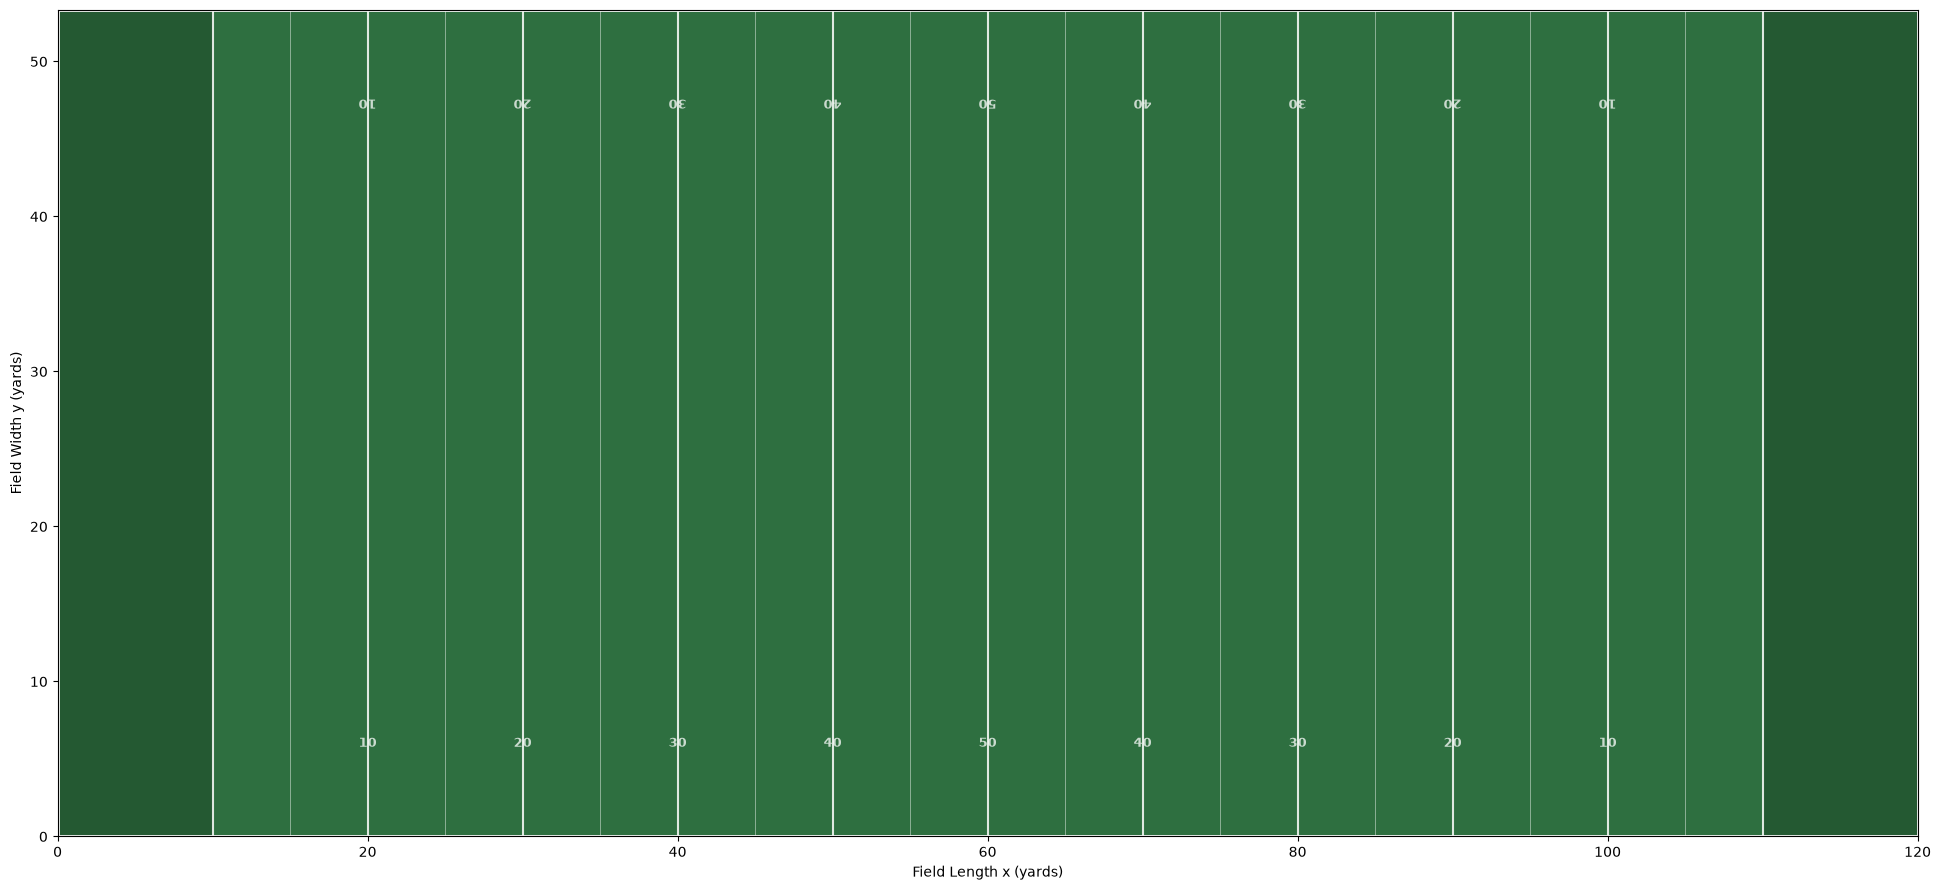

In [19]:
fig,ax = plt.subplots(figsize=(24,11))
draw_nfl_field(ax)

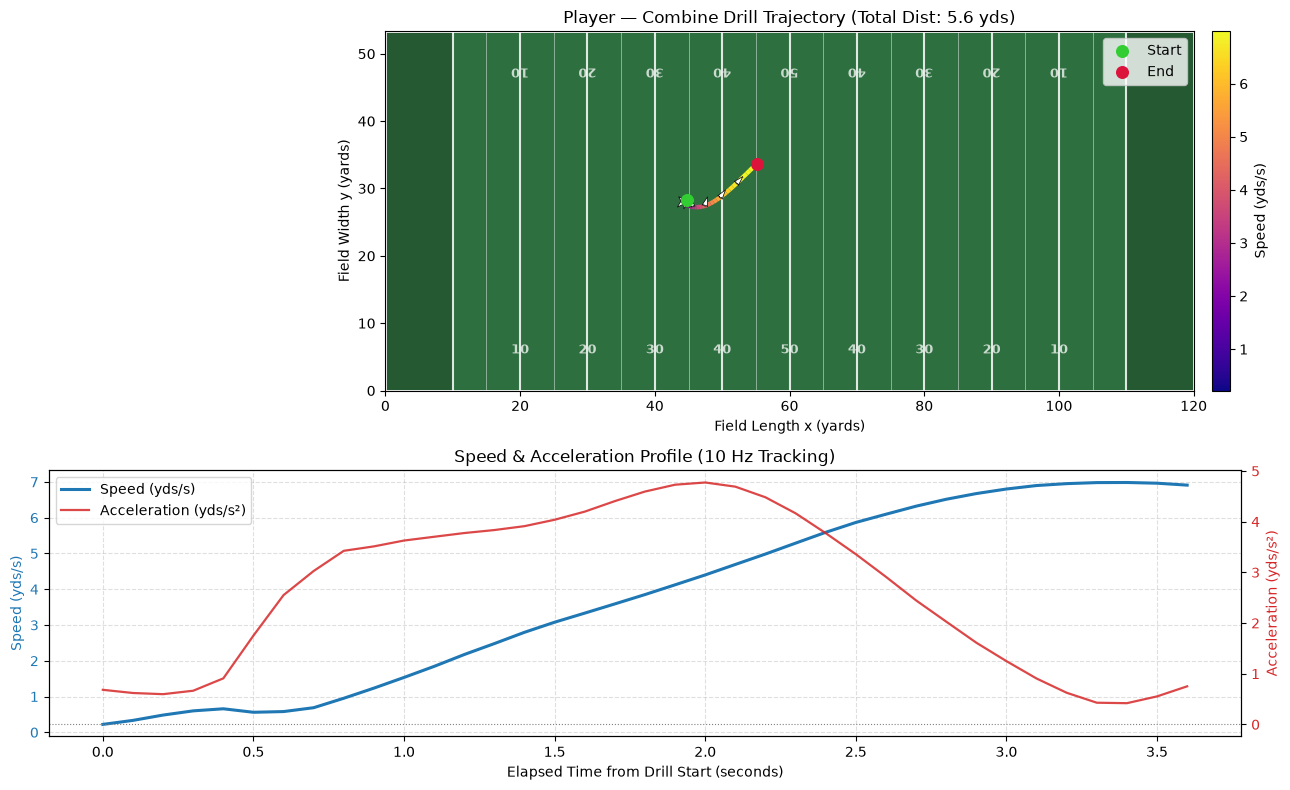

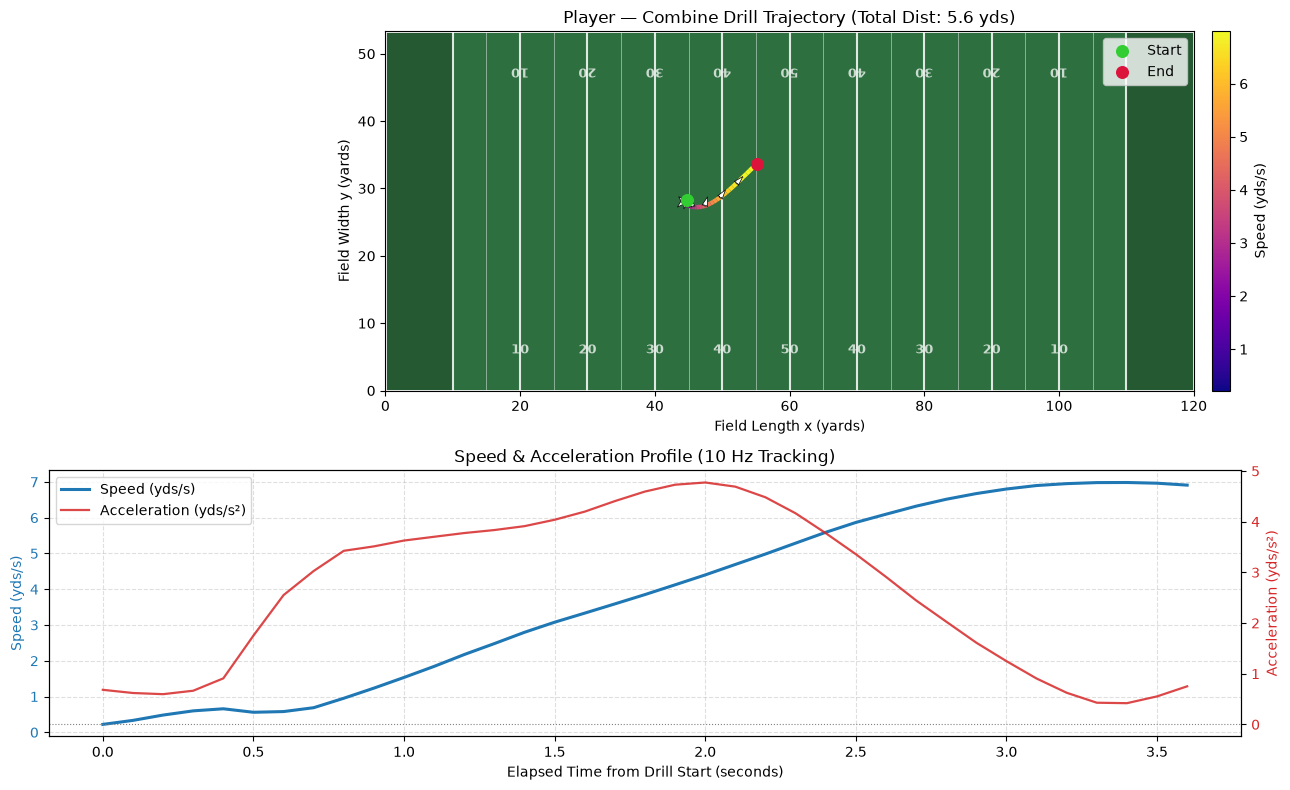

In [20]:
samples = combine_df.drop(columns=["draft_year", "drill_type", "drill_name", "entity_type"]).groupby(["event_id", "nfl_id", "attempt"], sort=False)
n, df = next(iter(samples))
plot_combine_drill(df)

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   event_id  37 non-null     str    
 1   nfl_id    37 non-null     int64  
 2   time      37 non-null     str    
 3   attempt   37 non-null     int64  
 4   x         37 non-null     float64
 5   y         37 non-null     float64
 6   s         37 non-null     float64
 7   a         37 non-null     float64
 8   dis       37 non-null     float64
 9   dir       37 non-null     float64
dtypes: float64(6), int64(2), str(2)
memory usage: 3.0 KB
